<a href="https://colab.research.google.com/github/grindstack/computer-vision_lab-task/blob/main/CV_lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Task 1:
!pip install numpy opencv-python matplotlib
import numpy as np
import cv2
import matplotlib.pyplot as plt
print('NumPy version :', np.__version__)
print('OpenCV version:', cv2.__version__)

NumPy version : 2.1.3
OpenCV version: 5.0.0


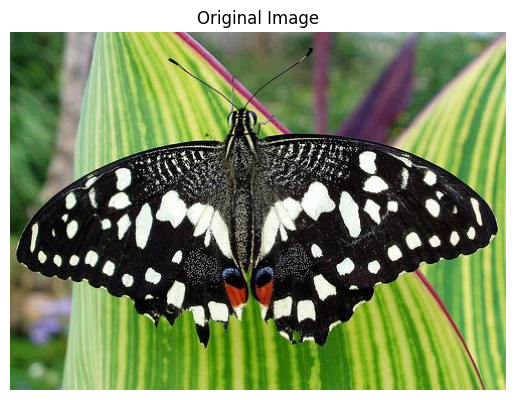

Image shape (H x W x Channels): (356, 493, 3)


In [3]:
# Task 2: Read and display an image
import urllib.request

# Download a sample image
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/butterfly.jpg"
urllib.request.urlretrieve(url, "sample.jpg")

# Read image (BGR)
img_bgr = cv2.imread('sample.jpg')

# Check if image loaded successfully
if img_bgr is not None:
    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Display image
    plt.imshow(img_rgb)
    plt.title('Original Image')
    plt.axis('off')
    plt.show()

    # Display image shape
    print('Image shape (H x W x Channels):', img_rgb.shape)
else:
    print("Image could not be loaded.")

Grayscale image shape (rows x cols) (356, 493)
Pixel matrix (top-left 5x5 block):
[[72 72 71 68 64]
 [75 73 69 64 60]
 [78 73 66 60 56]
 [77 73 66 59 55]
 [74 71 67 62 58]]


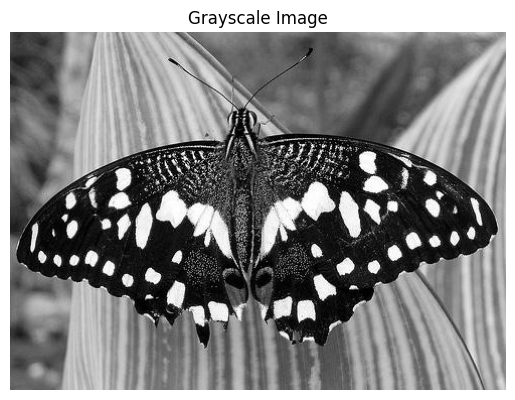

In [4]:
# Task 3: Grayscale conversion and matrix view
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
print('Grayscale image shape (rows x cols)', gray.shape)
print('Pixel matrix (top-left 5x5 block):')
print(gray[0:5, 0:5])
plt.imshow(gray, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')
plt.show()

In [5]:
# Task 4: Vector norm of an image row
row_vector = gray[100, :].astype(float) # 100th row as a vector

l1_norm = np.linalg.norm(row_vector, 1)
l2_norm = np.linalg.norm(row_vector, 2)
print('Row vector (first 10 values):', row_vector[:10])
print('L1 norm :', l1_norm)
print('L2 norm :', l2_norm)

Row vector (first 10 values): [72. 75. 79. 82. 84. 87. 91. 95. 95. 95.]
L1 norm : 69352.0
L2 norm : 3341.2473718657825


In [6]:
# Task 5: Dot product & cosine similarity
x = gray[100, :].astype(float)
y = gray[150, :].astype(float)
dot_xy = np.dot(x, y)
cos_sim = dot_xy / (np.linalg.norm(x) * np.linalg.norm(y))
print('Dot product :', dot_xy)
print('Cosine similarity:', cos_sim)

Dot product : 6209521.0
Cosine similarity: 0.7054363167066036


Original shape : (356, 493)
Transposed shape: (493, 356)


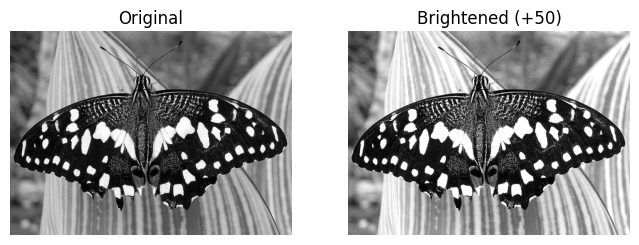

In [7]:
# Task 6: Matrix transpose and brightness adjustment
gray_transpose = gray.T
print('Original shape :', gray.shape)
print('Transposed shape:', gray_transpose.shape)
brighter = np.clip(gray.astype(int) + 50, 0, 255).astype(np.uint8)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(gray, cmap='gray'); ax[0].set_title('Original'); ax[0].axis('off')
ax[1].imshow(brighter, cmap='gray'); ax[1].set_title('Brightened (+50)'); ax[1].axis('off')
plt.show()

Scaling matrix: [[0.5 0. ]
 [0.  0.5]]


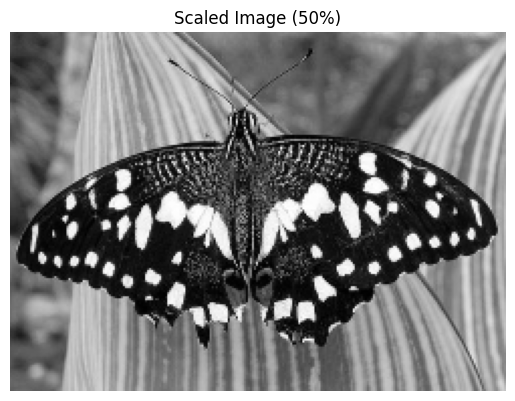

In [8]:
# Task 7: Scaling transformation
scale_x, scale_y = 0.5, 0.5
scale_matrix = np.array([[scale_x, 0], [0, scale_y]]) # 2x2 scaling matrix
print('Scaling matrix:', scale_matrix)
new_w = int(gray.shape[1] * scale_x)
new_h = int(gray.shape[0] * scale_y)
scaled_img = cv2.resize(gray, (new_w, new_h))
plt.imshow(scaled_img, cmap='gray')
plt.title('Scaled Image (50%)')
plt.axis('off')
plt.show()